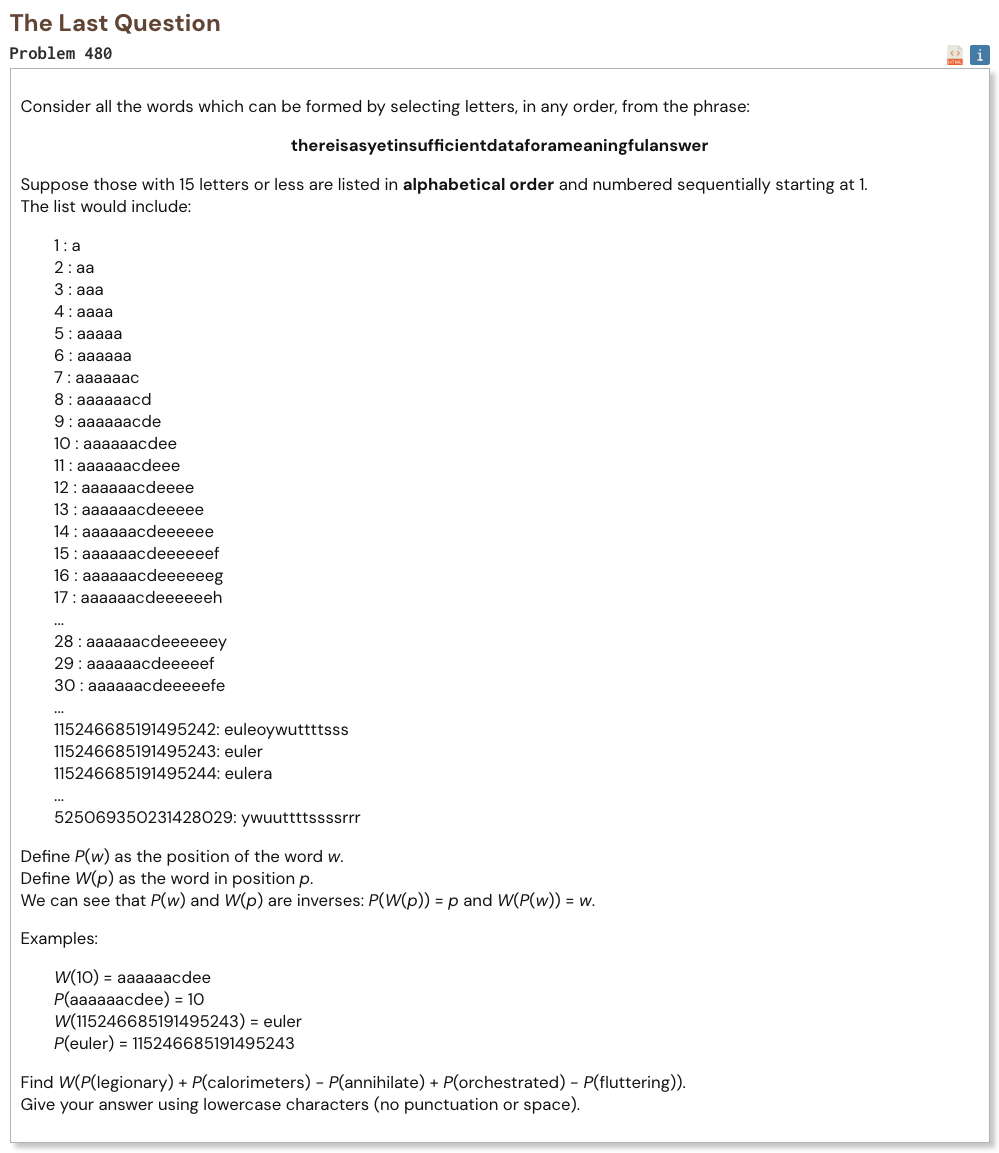

## Initial approach

- count how many valid words can be formed from each remaining multiset of letters
- use these counts to find the alphabetical position of any given word
- process the word one letter at a time and count all smaller possible prefixes first
- calculate the five required positions and combine them as requested
- reverse the process by locating which prefix contains the final position
- continue until the exact word is reconstructed

In [1]:
%%time

from collections import Counter
from functools import lru_cache
from math import comb

phrase = "thereisasyetinsufficientdataforameaningfulanswer"
max_length = 15

counter = Counter(phrase)
letters = tuple(sorted(counter))
initial_counts = tuple(counter[ch] for ch in letters)
letter_index = {ch: i for i, ch in enumerate(letters)}

@lru_cache(None)
def count_words(counts, slots):
    dp = [0] * (slots + 1)
    dp[0] = 1
    used = 0

    for available in counts:
        next_dp = [0] * (slots + 1)

        for length in range(min(used, slots) + 1):
            if dp[length] == 0:
                continue

            for take in range(min(available, slots - length) + 1):
                next_dp[length + take] += (
                    dp[length]
                    * comb(length + take, take)
                )

        dp = next_dp
        used += available

    return sum(dp)

def position(word):
    counts = list(initial_counts)
    rank = 0
    slots = max_length

    for ch in word:
        current = letter_index[ch]

        for i in range(current):
            if counts[i] > 0:
                counts[i] -= 1
                rank += count_words(tuple(counts), slots - 1)
                counts[i] += 1

        counts[current] -= 1
        rank += 1
        slots -= 1

    return rank

def word_at(rank):
    counts = list(initial_counts)
    slots = max_length
    result = []

    while slots > 0:
        for i, ch in enumerate(letters):
            if counts[i] == 0:
                continue

            counts[i] -= 1
            block = count_words(tuple(counts), slots - 1)

            if rank > block:
                rank -= block
                counts[i] += 1
                continue

            result.append(ch)
            slots -= 1

            if rank == 1:
                return "".join(result)

            rank -= 1
            break

    return "".join(result)

target = (
    position("legionary")
    + position("calorimeters")
    - position("annihilate")
    + position("orchestrated")
    - position("fluttering")
)

result = word_at(target)

print("Result:", result)

Result: turnthestarson
CPU times: user 32.9 ms, sys: 307 μs, total: 33.2 ms
Wall time: 33.3 ms
